# Day 2 — Computer Vision & Perception for UR5

Welcome to Day 2 of the **UR5 AI Workshop**!

### 🎯 Learning Objectives
By the end of this notebook, you will:
1. Capture and process images from a camera.
2. Apply computer vision algorithms (edges, contours, color filtering).
3. Use pre-trained AI models for object detection.
4. Map image coordinates to robot coordinates.


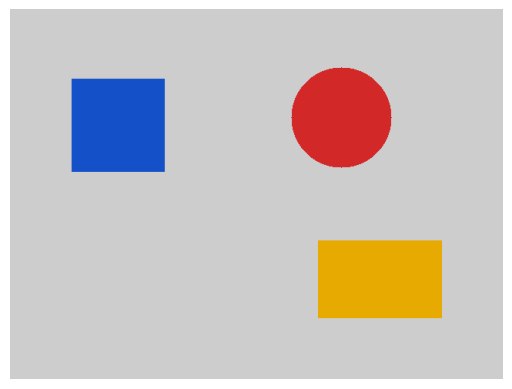

In [1]:
import cv2
import numpy as np
import matplotlib.pyplot as plt

def show(img):
    plt.imshow(cv2.cvtColor(img, cv2.COLOR_BGR2RGB))
    plt.axis('off')
    plt.show()

# test image with coloured shapes, in case there's no camera
scene = np.full((480, 640, 3), 205, np.uint8)
cv2.rectangle(scene, (80, 90), (200, 210), (200, 80, 20), -1)    # blue
cv2.circle(scene, (430, 140), 65, (40, 40, 210), -1)              # red
cv2.rectangle(scene, (400, 300), (560, 400), (0, 170, 230), -1)   # yellow
cv2.imwrite('test_scene.jpg', scene)
show(scene)


## 🧩 Exercise 1 — Capture and Display Images

qt.qpa.plugin: Could not find the Qt platform plugin "wayland" in "/home/errera/tn/cobot/.venv/lib/python3.12/site-packages/cv2/qt/plugins"


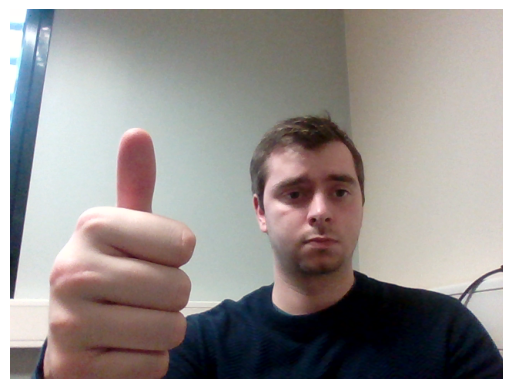

In [2]:
# Student Task:
cap = cv2.VideoCapture(0)
while True:
    ret, frame = cap.read()
    if not ret:
        frame = cv2.imread('test_scene.jpg')  # no camera -> use the test image
        cv2.imwrite('snapshot.jpg', frame)
        break
    cv2.imshow('UR5 Camera Feed', frame)
    if cv2.waitKey(1) & 0xFF == ord('q'):  # press q to take the snapshot
        cv2.imwrite('snapshot.jpg', frame)
        break
cap.release()
cv2.destroyAllWindows()
cv2.waitKey(1)
show(frame)


## 🧩 Exercise 2 — Basic Image Processing (Edges & Contours)

2 objects


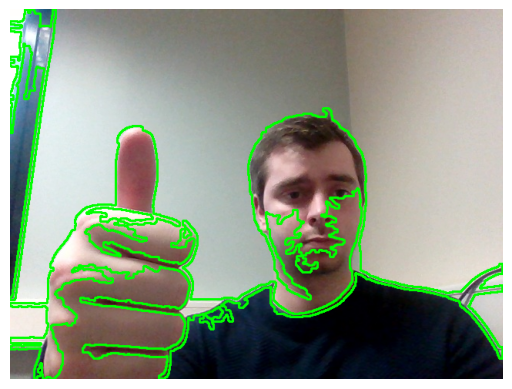

In [3]:
# Student Task:
img = cv2.imread('snapshot.jpg')
gray = cv2.cvtColor(img, cv2.COLOR_BGR2GRAY)
gray = cv2.GaussianBlur(gray, (5, 5), 0)  # less noise
edges = cv2.Canny(gray, 20, 60)
edges = cv2.dilate(edges, np.ones((5, 5), np.uint8))  # close gaps in the edges
contours, _ = cv2.findContours(edges, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
contours = [c for c in contours if cv2.contourArea(c) > 500]  # skip tiny ones
cv2.drawContours(img, contours, -1, (0, 255, 0), 2)
print(len(contours), 'objects')
show(img)


blue (140, 150)
red (430, 140)
yellow (481, 350)


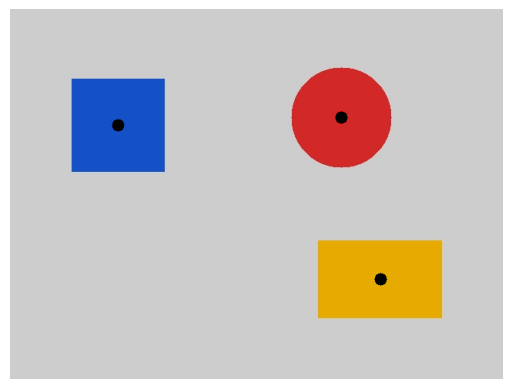

In [4]:
# Colour detection (from the slides): HSV mask -> biggest blob -> centre
COLORS = {'blue': ([100, 120, 50], [130, 255, 255]),
          'red': ([0, 120, 70], [10, 255, 255]),
          'yellow': ([20, 100, 80], [35, 255, 255])}

def find_color(img, color):
    hsv = cv2.cvtColor(img, cv2.COLOR_BGR2HSV)
    lower, upper = COLORS[color]
    mask = cv2.inRange(hsv, np.array(lower), np.array(upper))
    contours, _ = cv2.findContours(mask, cv2.RETR_EXTERNAL, cv2.CHAIN_APPROX_SIMPLE)
    if not contours:
        return None
    x, y, w, h = cv2.boundingRect(max(contours, key=cv2.contourArea))
    return x + w // 2, y + h // 2

img = cv2.imread('test_scene.jpg')
for color in COLORS:
    center = find_color(img, color)
    print(color, center)
    if center:
        cv2.circle(img, center, 8, (0, 0, 0), -1)
show(img)


## 🧩 Exercise 3 — Object Detection using a Pre-trained Model

person: 98.8%


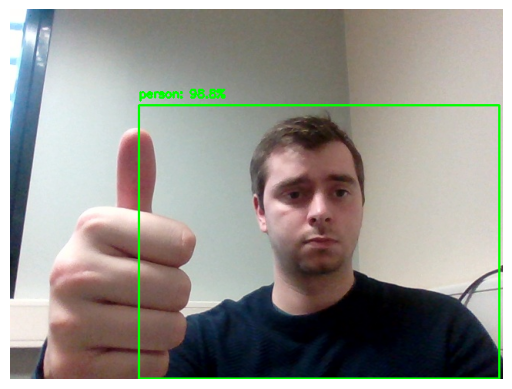

In [5]:
# Student Task:
net = cv2.dnn.readNetFromCaffe('models/MobileNetSSD_deploy.prototxt', 'models/MobileNetSSD_deploy.caffemodel')
classes = ['background','aeroplane','bicycle','bird','boat','bottle','bus','car','cat','chair',
           'cow','diningtable','dog','horse','motorbike','person','pottedplant','sheep','sofa','train','tvmonitor']

img = cv2.imread('snapshot.jpg')
h, w = img.shape[:2]
blob = cv2.dnn.blobFromImage(cv2.resize(img, (300,300)), 0.007843, (300,300), 127.5)
net.setInput(blob)
detections = net.forward()
for i in range(detections.shape[2]):
    confidence = detections[0,0,i,2]
    if confidence > 0.4:
        idx = int(detections[0,0,i,1])
        box = detections[0,0,i,3:7]*np.array([w,h,w,h])
        (startX, startY, endX, endY) = box.astype('int')
        label = f"{classes[idx]}: {confidence*100:.1f}%"
        print(label)
        cv2.rectangle(img, (startX, startY), (endX, endY), (0,255,0), 2)
        cv2.putText(img, label, (startX, startY-10), cv2.FONT_HERSHEY_SIMPLEX, 0.5, (0,255,0), 2)
show(img)


## 🧩 Exercise 4 — Pixel to Robot Coordinate Mapping

In [6]:
# Student Task:
# Pretend the camera looks down at a 40 x 30 cm area in front of the robot.
# The 4 image corners map to the 4 corners of that area (robot X, Y in metres).
pixels = np.float32([[0, 0], [640, 0], [640, 480], [0, 480]])
robot = np.float32([[-0.60, 0.20], [-0.60, -0.20], [-0.30, -0.20], [-0.30, 0.20]])
H, _ = cv2.findHomography(pixels, robot)

def pixel_to_robot(px, py):
    X, Y = cv2.perspectiveTransform(np.float32([[[px, py]]]), H)[0, 0]
    return float(X), float(Y)

print(pixel_to_robot(320, 240))  # image centre -> (-0.45, 0.0)
print(pixel_to_robot(200, 150))


(-0.45000001788139343, -2.7755575615628914e-17)
(-0.5062500238418579, 0.07500000298023224)


## 🎓 Final Challenge — Vision-Guided Pick Simulation
Combine all steps:
1. Detect an object (color or model-based).
2. Compute its pixel center.
3. Convert to robot coordinates.
4. Send a move command to URSim to align the TCP above the object.

**Hint:** Reuse your `pixel_to_robot()` and UR RTDE control interface.

In [10]:
import math
from rtde_control import RTDEControlInterface
from rtde_receive import RTDEReceiveInterface

rtde_c = RTDEControlInterface('127.0.0.1')  # Day 1 notebook must be disconnected first
rtde_r = RTDEReceiveInterface('127.0.0.1')

# 1-2. detect the object and get its pixel centre
img = cv2.resize(cv2.imread('test_scene.jpg'), (640, 480))  # or 'snapshot.jpg'
px, py = find_color(img, 'blue')

# 3. convert to robot coordinates
X, Y = pixel_to_robot(px, py)
print('object at pixel', (px, py), '-> robot', (round(X, 3), round(Y, 3)))

# 4. move above it with the tool pointing down, go down, come back up
down = [0, math.pi, 0]
rtde_c.moveJ([-0.301, -1.528, 2.179, -2.221, -1.571, -1.872], 0.5, 0.5)  # start pose above the table
rtde_c.moveL([X, Y, 0.20] + down, 0.25, 0.5)   # above the object
rtde_c.moveL([X, Y, 0.10] + down, 0.25, 0.5)   # "pick"
rtde_c.moveL([X, Y, 0.20] + down, 0.25, 0.5)   # lift
print('tool now at', [round(v, 3) for v in rtde_r.getActualTCPPose()[:3]])

rtde_c.stopScript()
rtde_c.disconnect()
rtde_r.disconnect()


object at pixel (140, 150) -> robot (-0.506, 0.113)
tool now at [-0.506, 0.113, 0.2]
